# AI-рекомендации: стоит ли запускать модель?

Маркетплейс 30 дней тестировал новую модель рекомендаций на главной странице.
Сравним продажи, маржу и последствия для покупателей, затем выберем следующий шаг.
Данные синтетические; период эксперимента — **1–30 июля 2026 года**.

In [1]:
from pathlib import Path
import json
import hashlib
import pandas as pd
from IPython.display import display, Markdown
from src.presentation import metric_table, main_figure, risk_figure, device_figure, show_figure

# Используем проверенные результаты; полный расчёт запускается через run_analysis.py.
ROOT = Path.cwd()
folder = ROOT / "reports" / "tables"
meta = json.loads((ROOT / "reports" / "run_metadata.json").read_text())
for filename, expected in meta["source_sha256"].items():
    assert hashlib.sha256((ROOT / filename).read_bytes()).hexdigest() == expected, "Обновите расчёты"
assert meta["config"]["alpha"] == 0.05, "Для другого уровня доверия обновите итоговое изложение"
metrics = pd.read_csv(folder / "metrics.csv").set_index("metric")
segments = pd.read_csv(folder / "segment_effects.csv")
interactions = pd.read_csv(folder / "interactions.csv")
sensitivity = pd.read_csv(folder / "sensitivity.csv")

## Что вошло в сравнение

В исходных данных 50 000 пользователей. После исключения ботов и пользователей,
назначенных сразу в обе группы, осталось **49 301**: 24 473 в control и 24 828 в test.
До очистки проверка соотношения групп не обнаружила нарушения ожидаемого распределения 50/50
(χ², p = 0,098). Выводы относятся к этой очищенной аудитории.

Все события одного пользователя учитывались совместно. Для средних использовали
Welch t-test, для пользовательских долей — Z-test/Фишер, для CTR — расчёт ошибки
с учётом повторных событий. Значимость проверяли с поправкой на несколько гипотез.

## Продажи и маржа выросли

Новые рекомендации чаще приводят к кликам и покупкам. Рост GMV связан прежде всего
с увеличением конверсии: убедительного изменения среднего чека не обнаружено.

,Control,Test,Разница,95% ДИ разницы,p с поправкой
Метрика,,,,,
"GMV на пользователя, ₽",211.15,286.41,+75.27 ₽,[59.15; 91.39] ₽,"< 0,001"
"Записанная маржа на пользователя, ₽",35.11,46.32,+11.21 ₽,[8.63; 13.79] ₽,"< 0,001"
"CTR, %",7.31,9.02,+1.72 п.п.,[1.61; 1.83] п.п.,"< 0,001"
"Конверсия в покупку, %",11.81,15.17,+3.36 п.п.,[2.76; 3.97] п.п.,"< 0,001"
"Средний чек, ₽",1663.14,1685.10,+21.95 ₽,[-54.47; 98.38] ₽,0.662


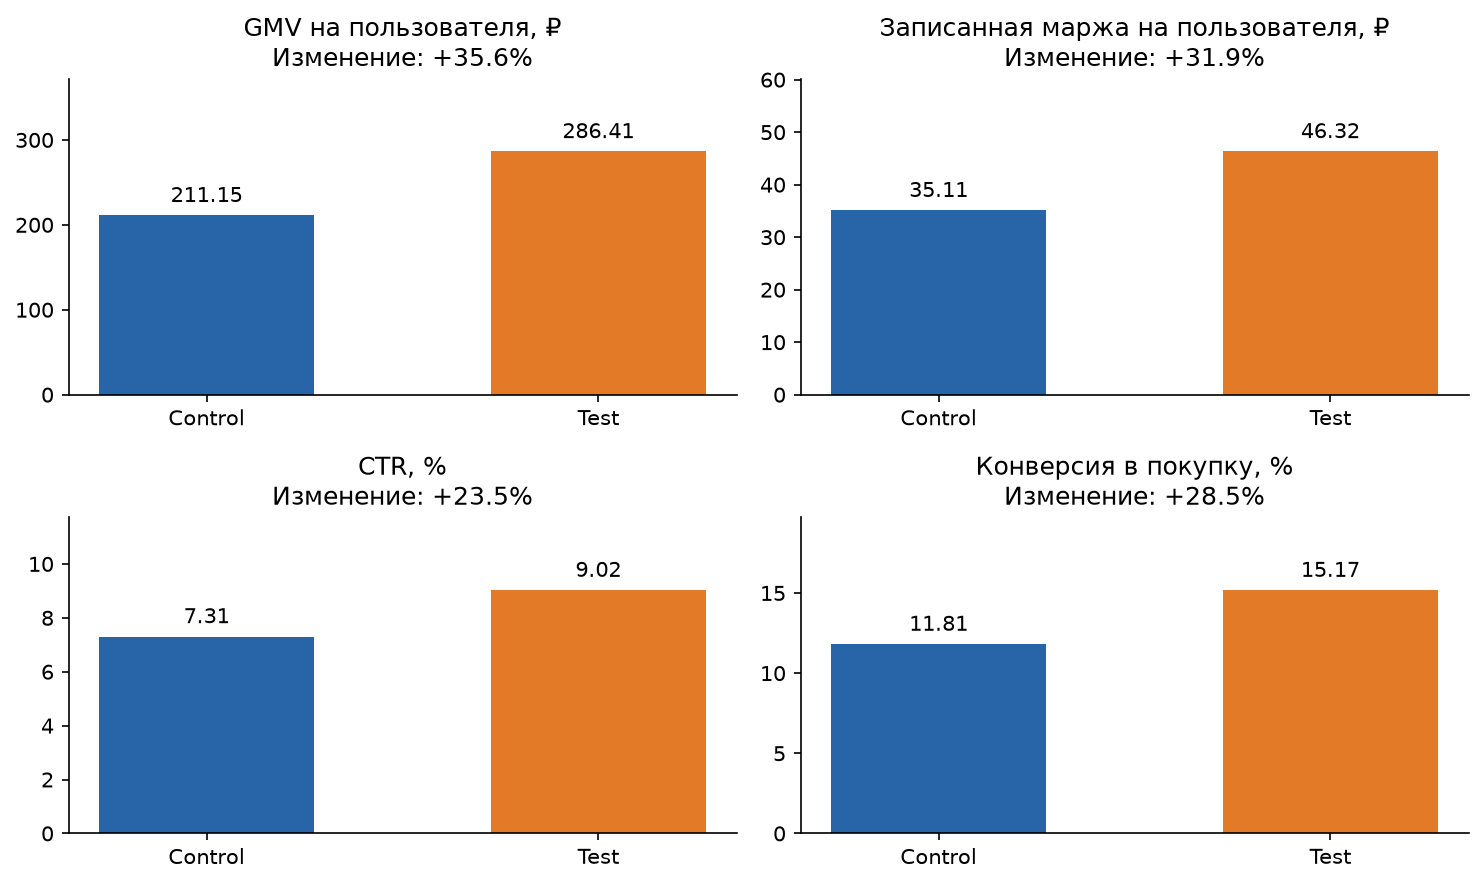

In [2]:
display(metric_table(metrics, ["gmv_user", "margin_user", "ctr", "buyer_conversion", "aov"]))
show_figure(main_figure(metrics), "01_sales", ROOT)

In [3]:
gmv, margin = metrics.loc["gmv_user"], metrics.loc["margin_user"]
display(Markdown(
    f"На одного пользователя модель добавляет **{gmv.effect:.1f} ₽ GMV "
    f"(+{gmv.relative_effect_pct:.1f}%)** и **{margin.effect:.1f} ₽ записанной маржи "
    f"(+{margin.relative_effect_pct:.1f}%)**. Интервал прироста GMV — "
    f"от {gmv.ci_low:.1f} до {gmv.ci_high:.1f} ₽; интервалы на графиках и в таблицах — индивидуальные, до поправки."
))

На одного пользователя модель добавляет **75.3 ₽ GMV (+35.6%)** и **11.2 ₽ записанной маржи (+31.9%)**. Интервал прироста GMV — от 59.1 до 91.4 ₽; интервалы на графиках и в таблицах — индивидуальные, до поправки.

Маржа в выгрузке уже учитывает записанные возвраты, в том числе после окончания
эксперимента. Это не маржа на 30-й день и не чистая прибыль: состав расходов
на AI, доставку и поддержку нужно уточнить.

## Покупок больше — проблем после покупки тоже

За время эксперимента в test больше пользователей столкнулись с возвратом или
обратились в поддержку. Оба увеличения статистически значимы после поправки Holm.
На графике показано число таких пользователей на каждую тысячу назначенных.

,Control,Test,Разница,95% ДИ разницы,p с поправкой
Метрика,,,,,
"Пользователи с возвратом за 30 дней, %",0.25,0.39,+0.15 п.п.,[0.05; 0.25] п.п.,0.004
"Пользователи с обращением за 30 дней, %",0.48,0.76,+0.28 п.п.,[0.14; 0.42] п.п.,"< 0,001"


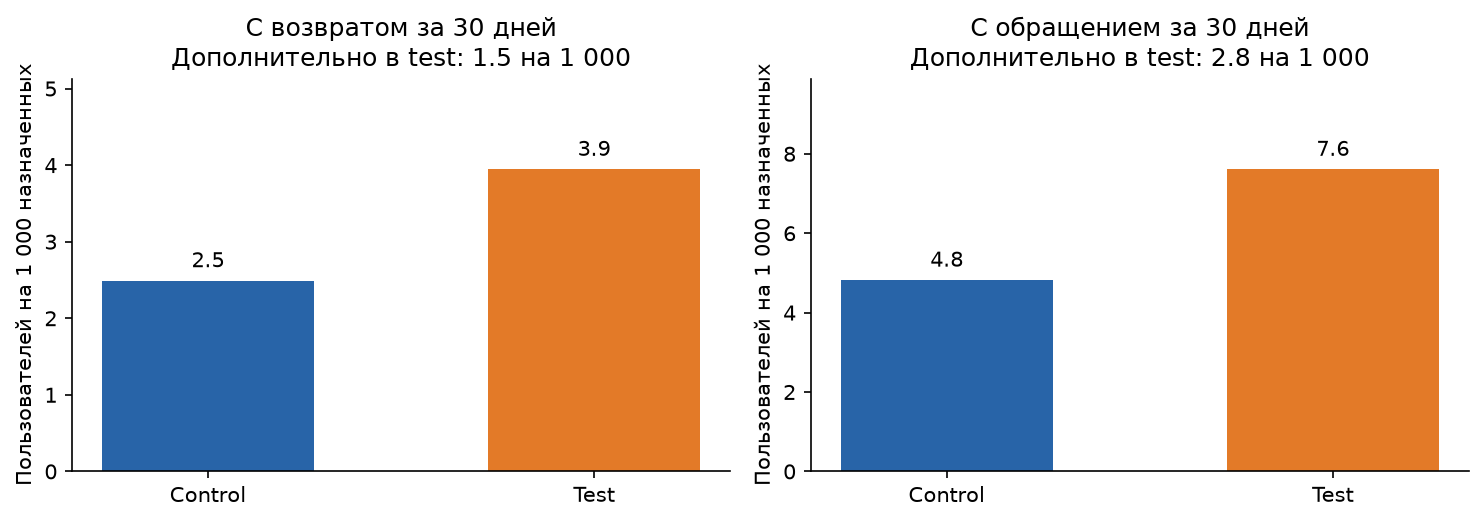

С учётом записанных поздних возвратов доля возвращённых заказов составляет **5.54% в control и 6.82% в test**. Это предварительное сравнение: дата полной выгрузки неизвестна, и одинаковый срок наблюдения после каждой покупки не подтверждён.

In [4]:
display(metric_table(metrics, ["return_user_window", "support_user_window"]))
show_figure(risk_figure(metrics), "02_customer_impact", ROOT)
returns = metrics.loc["return_rate_observed"]
display(Markdown(
    f"С учётом записанных поздних возвратов доля возвращённых заказов составляет "
    f"**{returns.control:.2%} в control и {returns.test:.2%} в test**. "
    "Это предварительное сравнение: дата полной выгрузки неизвестна, "
    "и одинаковый срок наблюдения после каждой покупки не подтверждён."
))

## Эффект зависит от устройства

Самый большой прирост GMV и маржи наблюдается на Android. На iOS выигрыш меньше,
а для web данных недостаточно, чтобы уверенно подтвердить рост.
Различия по устройствам подтверждены совместной проверкой эффектов, а не только
сравнением значимости отдельных сегментов.

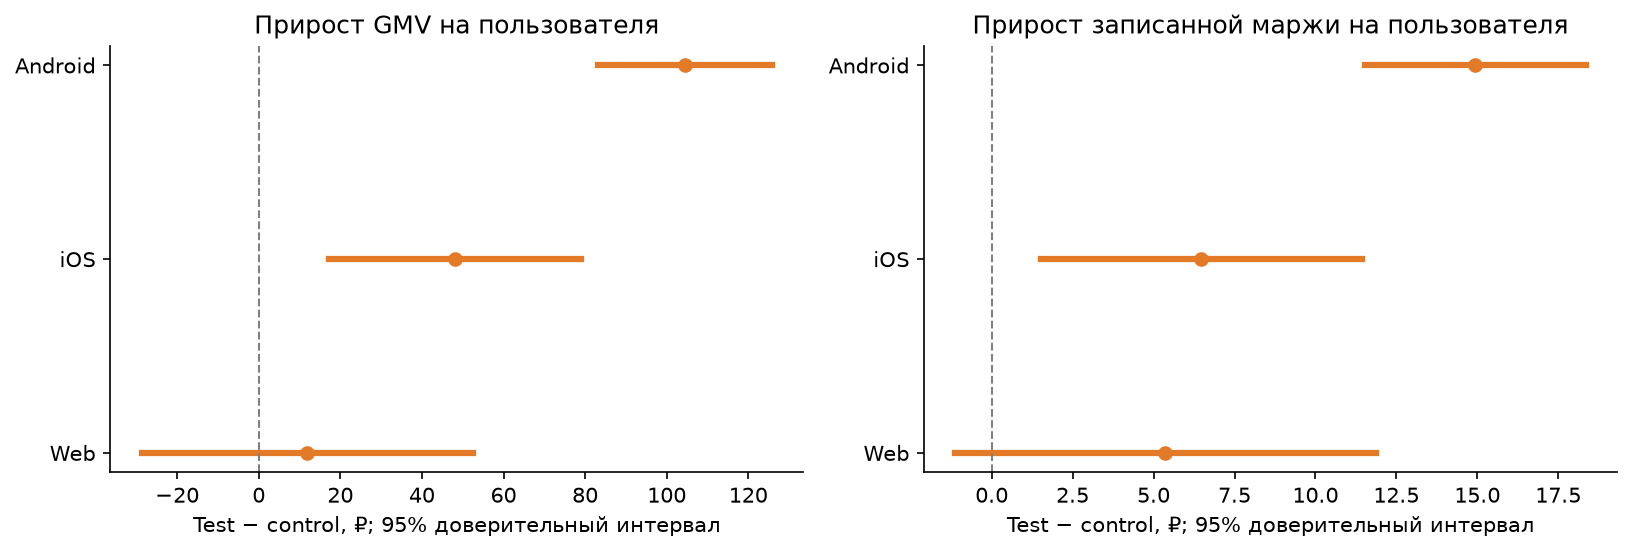

Прирост GMV: Android — **+104.4 ₽/польз.**, iOS — +48.1 ₽, web — +11.9 ₽. p для различий между устройствами после FDR = 0.0008. На Android также растут обращения в поддержку, поэтому большой выигрыш не означает, что сегмент уже готов к запуску.

In [5]:
show_figure(device_figure(segments), "03_devices", ROOT)
device_gmv = segments.query("segment == 'device' and metric == 'gmv_user'").set_index("level")
device_test = interactions.query("segment == 'device' and metric == 'gmv_user'").iloc[0]
display(Markdown(
    f"Прирост GMV: Android — **+{device_gmv.loc['android', 'effect']:.1f} ₽/польз.**, "
    f"iOS — +{device_gmv.loc['ios', 'effect']:.1f} ₽, web — +{device_gmv.loc['web', 'effect']:.1f} ₽. "
    f"p для различий между устройствами после FDR = {device_test.p_adjusted:.4f}. "
    "На Android также растут обращения в поддержку, поэтому большой выигрыш не означает, что сегмент уже готов к запуску."
))

## Насколько устойчив результат

Bootstrap подтверждает вывод о росте GMV и маржи. Включение ботов, использование
первичного назначения и ограничение денежного хвоста не меняют направление эффекта.
Исключение помеченных показов также практически не меняет CTR.

In [6]:
growth = sensitivity.query("metric == 'gmv_user'").relative_effect_pct
display(Markdown(
    f"В проверках устойчивости относительный прирост GMV лежит в диапазоне "
    f"**{growth.min():.1f}–{growth.max():.1f}%**. Поэтому результат не выглядит следствием одного правила очистки."
))

В проверках устойчивости относительный прирост GMV лежит в диапазоне **35.1–35.6%**. Поэтому результат не выглядит следствием одного правила очистки.

## Решение

**Полный запуск пока не рекомендую. Следующий шаг — ограниченный пилот на Android
с сохранением контрольной группы.** Модель даёт заметный выигрыш в продажах и
записанной марже, однако одновременно увеличивает нагрузку на поддержку и возвраты.
Сегмент найден в этом эксперименте, поэтому его результат стоит подтвердить.

До расширения пилота нужно:

1. Задать допустимое увеличение возвратов и обращений. Незначимый вред не равен безопасности.
2. Подтвердить полное наблюдение поздних возвратов за одинаковый срок после заказа.
3. Уточнить расходы на AI и поддержку и проверить, что выигрыш сохраняется после их учёта.

Если эти условия выполняются и эффект повторяется в пилоте, можно расширять охват.
Для web сначала нужен более убедительный результат.

Полные проверки доступны в [подробном ноутбуке](analysis_full.ipynb),
[таблицах результатов](reports/tables/) и [исходном коде](src/).